# Viz comparison: real graph against synthetic graphs

Plots of how the real ego-Facebook graph and the synthetic graphs behave, side by side. Black is always the **real**
graph; the coloured lines and bars are **synthetic** graphs generated outside from an artifact. This notebook lives in
`snap/eval/` because it needs both: the real graph (from `snap/inside/data`) and the synthetic graphs (from
`snap/outside/synthetic`). The plotting code is `src/graph_aim/eval/viz.py`.

How to read the plots: the synthetic graph is a *new* graph, so nodes are not matched one to one; only
distributions and patterns can be compared. Each section says what to look for, and the last part gives small
concrete examples (neighbourhoods and a connected patch) next to each other.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

NB = Path.cwd()
EVAL = NB.parent if NB.name == "notebooks" else NB          # snap/eval
SNAP = EVAL.parent
sys.path.insert(0, str(SNAP.parent / "src"))

from graph_aim.eval import viz
from graph_aim.eval.evaluate import align_columns, comparison_table, degrees
from graph_aim.transfer.graph_io import load_attributed_graph

from IPython.display import display

plt.rcParams["figure.dpi"] = 110


def show(fig):
    # display explicitly (works on any backend), then free the figure
    display(fig)
    plt.close(fig)

real = load_attributed_graph(SNAP / "inside" / "data" / "processed" / "attributed_graph.npz")
ATTR = json.loads((SNAP / "inside" / "config" / "graph_aim_v1.json").read_text())["homophily_attrs"][0]

# label -> file written by stage 2 (snap/outside/generate_synthetic.py). Add others, e.g. "graph_aim_eps1_seed0".
SYNTHETIC = {
    "graph_aim eps=4": "graph_aim_eps4_seed0",
    "graph_aim non-private": "graph_aim_nocap_nonprivate_seed0",
}
syns = {
    label: align_columns(load_attributed_graph(SNAP / "outside" / "synthetic" / f"{stem}.npz"), real)
    for label, stem in SYNTHETIC.items()
    if (SNAP / "outside" / "synthetic" / f"{stem}.npz").exists()
}
for label, g in {"real": real, **syns}.items():
    print(f"{label:24s} nodes {g.n}  edges {len(g.edges):6d}  mean degree {2 * len(g.edges) / g.n:5.1f}  max degree {degrees(g).max()}")
print("attribute used for colours and homophily:", ATTR)

real                     nodes 4039  edges  88234  mean degree  43.7  max degree 1045
graph_aim eps=4          nodes 4039  edges  91296  mean degree  45.2  max degree 771
graph_aim non-private    nodes 4039  edges  87922  mean degree  43.5  max degree 825
attribute used for colours and homophily: school


## 1. Degrees

Left: the share of nodes with at least *k* friends (a straight line on log-log axes means a heavy tail). Right: every
node's degree sorted from the biggest hub down, which shows the hubs directly. *Look for:* does the synthetic curve
follow the black one in the bulk, and does it reach the same hubs at the far end?

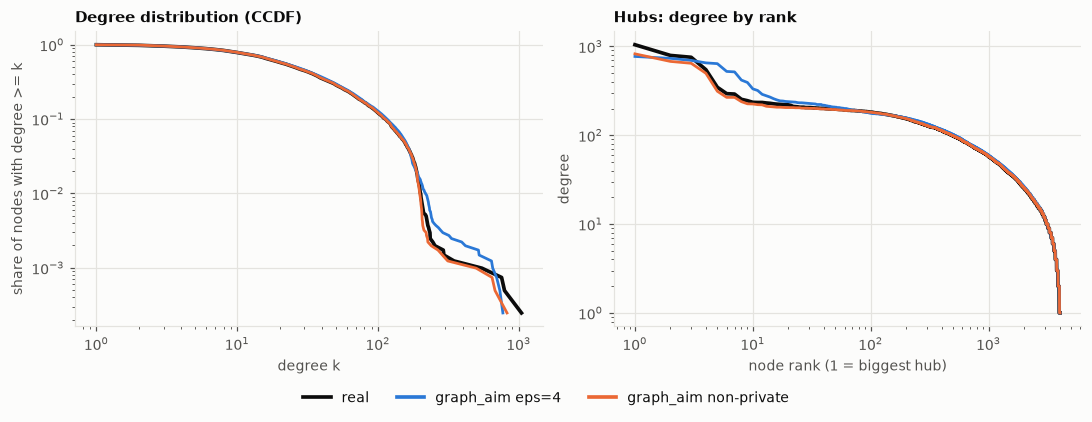

In [2]:
show(viz.degree_distribution(real, syns))

**What we see.** The bulk matches almost exactly (the three lines overlap up to degree ~100). At the far end the synthetic graphs stop short of the biggest real hubs: the largest synthetic degree is around 800 against 1,045 in the real graph, and the eps=4 graph has a few more mid-sized hubs than the real one (ranks ~8 to 20).

## 2. Clustering: do friends of friends know each other?

Left: average local clustering of nodes with the same degree. Right: the spread of local clustering over all nodes.
*Look for:* the level and the downward slope with degree (hubs have lower clustering than ordinary people).

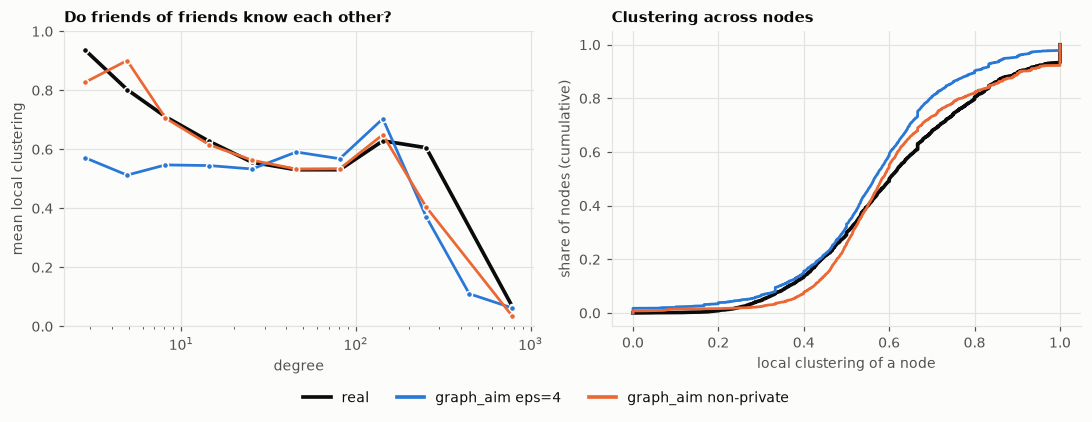

In [3]:
show(viz.clustering_by_degree(real, syns))

**What we see.** The non-private graph follows the real curve closely, including the fall for hubs above degree ~200. The eps=4 graph is flat at about 0.55 below degree 30, so it misses the very high clustering of low-degree people (0.8 to 0.95 in the real graph). On the right, the eps=4 graph has more nodes with low-to-middle clustering and fewer with clustering of exactly 1.

## 3. Who connects to whom, by degree

Each heatmap row is a degree class; the colours show where that class's friends sit (also by degree). A bright
diagonal means hubs know hubs; a bright first column means everyone knows the low-degree nodes. The title gives the
assortativity coefficient. The curve below shows the average degree of a person's friends against their own degree.

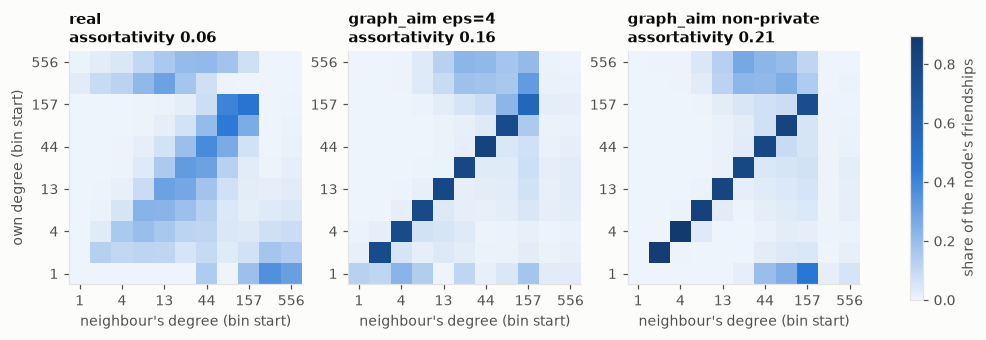

In [4]:
show(viz.degree_mixing(real, syns))

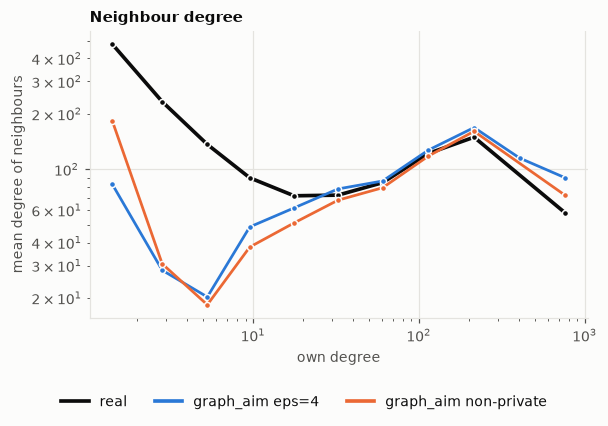

In [5]:
show(viz.neighbor_degree(real, syns))

**What we see.** This is where the synthetic graphs differ most in *shape*. In the real graph, low-degree people connect mostly to hubs (bottom right) and friendships are spread across degree classes. In both synthetic graphs friendships concentrate on the diagonal, between nodes of similar degree, and low-degree nodes rarely attach to hubs (neighbour-degree curve below: below degree 10 the friends of real nodes have an average degree of 90 to 470, those of synthetic nodes mostly 20 to 80, with the non-private graph reaching ~180 only for degree-1 nodes). The single assortativity number (0.06 real against 0.16 and 0.21) understates how different the pattern is.

## 4. Distances and dense cores

Left: how many hops separate two random people. Right: how many nodes belong to a dense core (the k-core is the part
of the graph where everyone has at least k friends inside it).

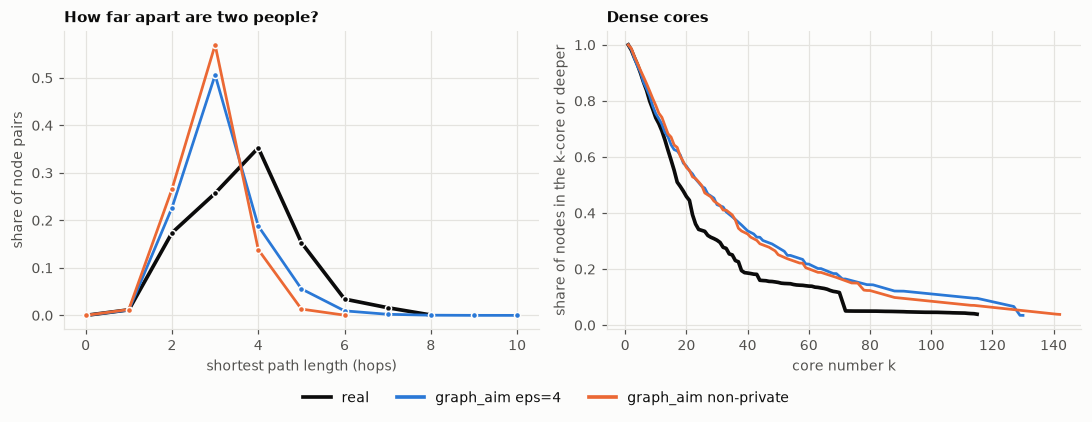

In [6]:
show(viz.paths_and_cores(real, syns))

**What we see.** The synthetic graphs are more compact: the typical distance between two people is 3 hops against 4 in the real graph. Both synthetic graphs also have more nodes in deep cores and a deepest core of about 130 to 140, against about 115 in the real graph.

## 5. Attributes

Node attributes are anonymized profile fields (education, work, location, ...). The labels such as `538` are the
anonymized value ids; `other` and `none` are the explicit leftovers.

**5a. How common is each value.** The bars compare the share of nodes per value.

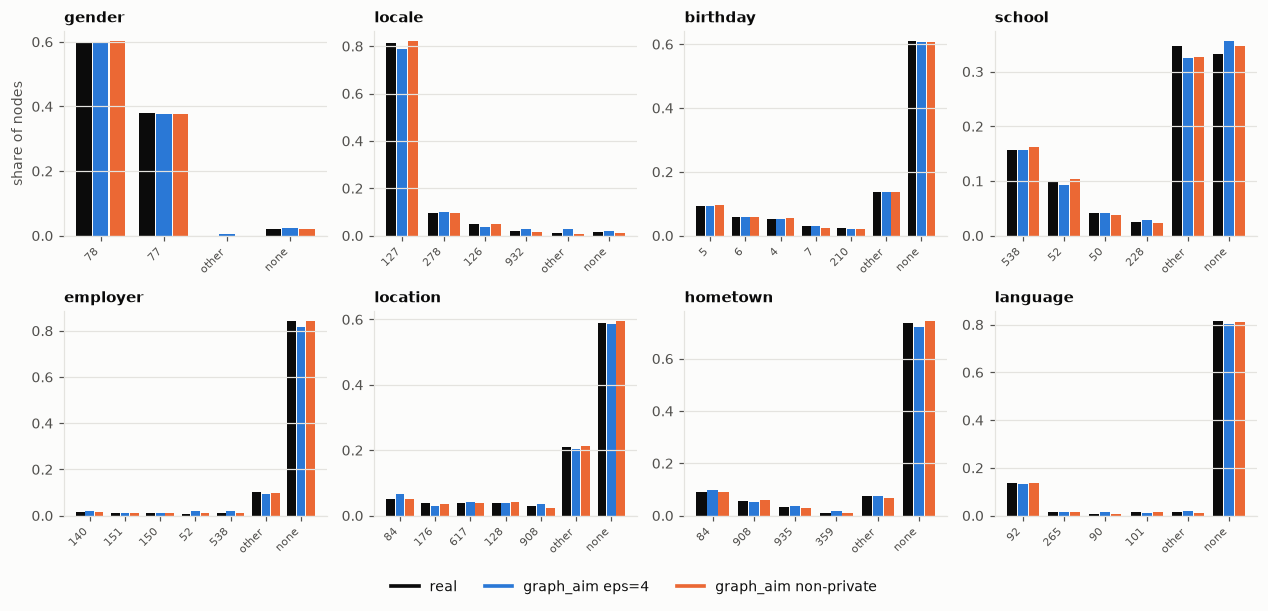

In [7]:
show(viz.attribute_marginals(real, syns))

**What we see.** How common each value is matches closely for all eight attributes in both synthetic graphs. The only visible deviations are tiny shares on rare values at eps=4 (for example a small 'other' share for gender where the real graph has none).

**5b. Do friends share attributes (homophily).** For people in a group of `ATTR` (rows), where do their friends fall
(columns)? Numbers are percent of friendships; a strong diagonal means friends tend to be in the same group.

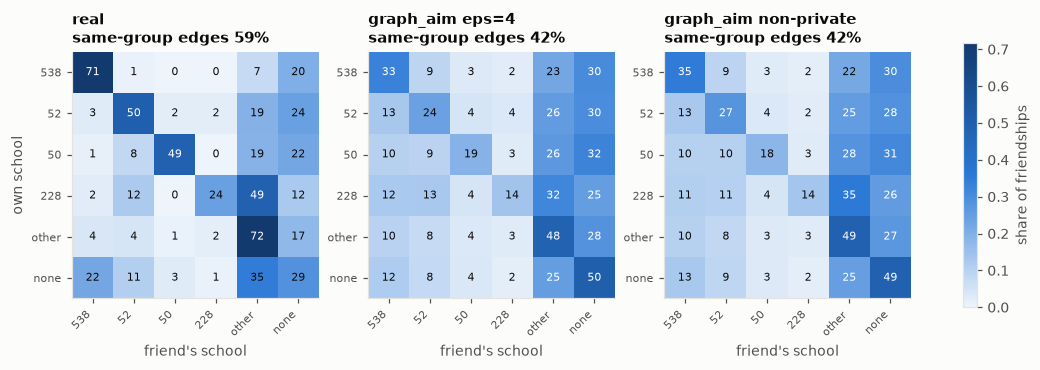

In [8]:
show(viz.homophily(real, syns, ATTR))

**What we see.** The pattern is kept but weakened. In the real graph 59% of friendships connect people of the same school group (71% of school 538's friendships stay inside 538); in the synthetic graphs it is about 42% (about 33% for school 538). Both synthetic graphs show the same weakened diagonal, so this limit comes from the generator and not from the privacy noise.

**5c. Do attributes go together.** Association (Cramer's V, 0 = independent) between each pair of node attributes in the
real graph, in the synthetic graph, and their difference. Orange means the synthetic pair is *more* associated than
the real one, blue less.

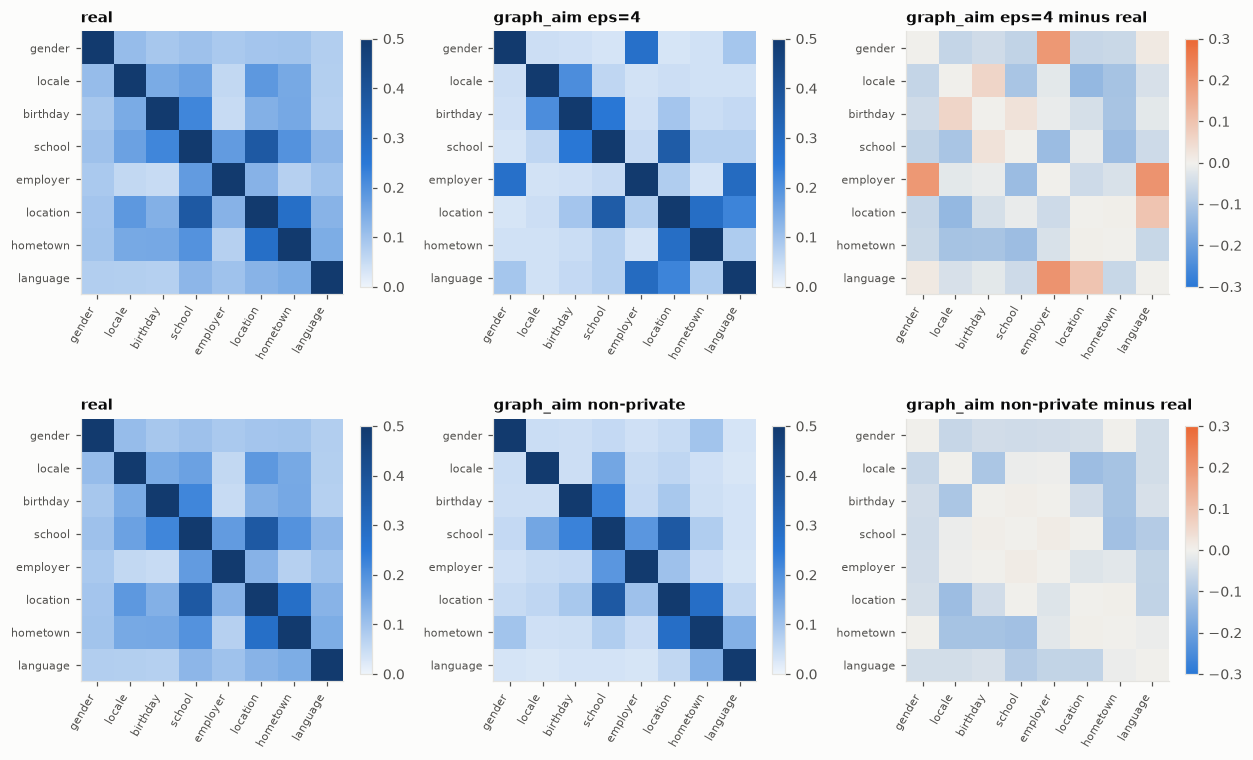

In [9]:
show(viz.attribute_association(real, syns))

**What we see.** Most attribute pairs have similar strength to the real graph. The eps=4 graph overstates a few pairs involving employer (employer with gender and with language, orange), probably noise on very rare employer values. The non-private graph tends to understate associations slightly (blue).

## 6. Small examples

The same selection rule is applied to every graph: take the node whose degree is closest to the target, and among
nodes with that degree the one with median clustering. So these are typical, not cherry-picked, neighbourhoods.

**6a. One person and their friends.** The ringed dot is the person, the others are their friends coloured by `ATTR`,
lines are friendships among them. Columns are increasing degree.

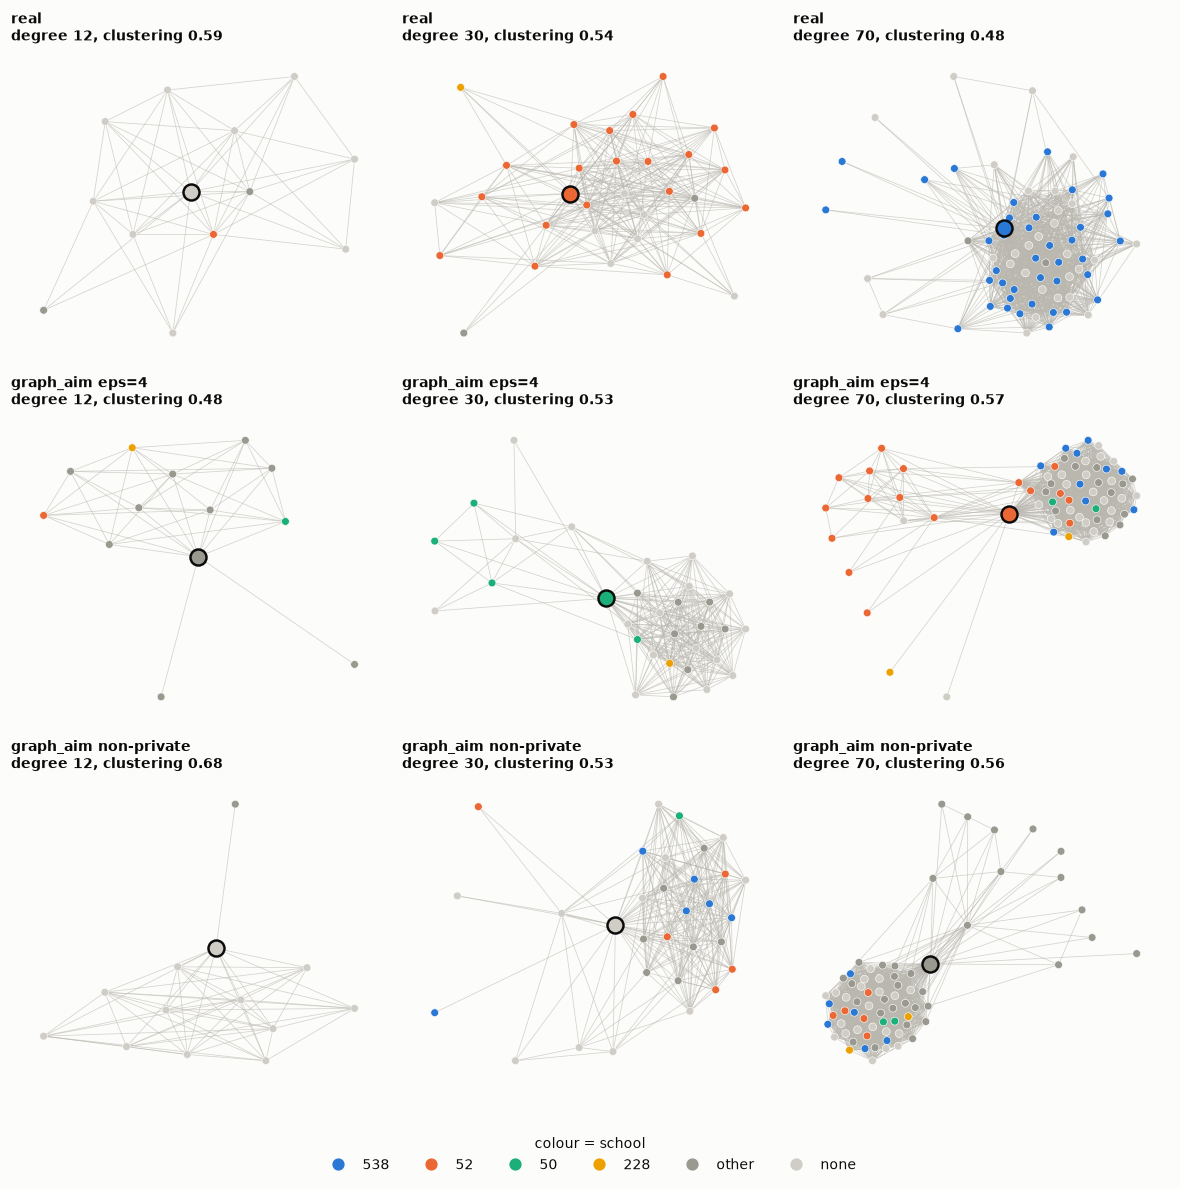

In [10]:
show(viz.ego_examples(real, syns, ATTR, targets=(12, 30, 70)))

**What we see.** Real neighbourhoods are colour-coherent: the degree-30 and degree-70 people have friends mostly from one school group, and the ego sits inside the dense core. The synthetic neighbourhoods have a plausible size and density with a dense core plus loose extras, but their colours are mixed, and at degree 70 the person sits at the edge of the dense cluster instead of inside it.

**6b. A connected patch of 60 nodes** found by walking outward from a typical node, so it shows what the local structure
and the colours look like around somebody.

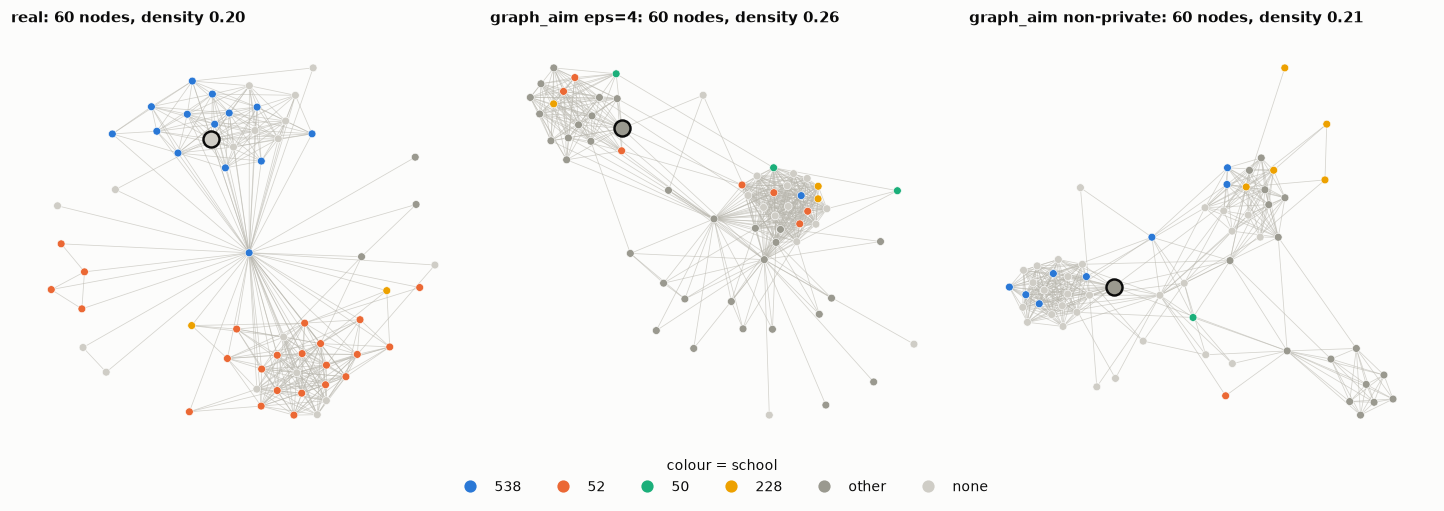

In [11]:
show(viz.bfs_sample(real, syns, ATTR, size=60, start_degree=20))

**What we see.** The real patch shows two school-coloured communities (blue and orange) connected through a single hub. The synthetic patches also have dense clusters joined by connector nodes, but the colours are mixed inside each cluster: the communities exist structurally, they are not aligned with the school attribute.

## 7. The numbers behind the pictures

Distances to the real graph (0 = identical on that statistic; lower is better). See
`snap/eval/results/` for the multi-seed sweep and `snap/reports/graph_aim_v1.md` for the write-up.

In [12]:
comparison_table(real, syns, homophily_attrs=[ATTR]).round(3)

,graph_aim eps=4,graph_aim non-private
degree_ks,0.016,0.006
degree_emd,1.817,0.335
clustering_abs,0.049,0.003
clustering_rel,0.081,0.004
transitivity_abs,0.016,0.002
transitivity_rel,0.031,0.004
triangles_abs,72225.000,90034.000
triangles_rel,0.045,0.056
path_length_abs,0.543,0.758
path_length_rel,0.149,0.209


## Caveats

- One synthetic graph per setting (seed 0). Different seeds give different graphs; the sweep in `snap/eval/results/`
  shows the spread, which is large for the hubs.
- These plots compare distributions, not individual nodes: synthetic nodes are not matched to real ones.
- The synthetic graphs come from artifacts with differential privacy noise at eps = 4 per adjacency (and a non-private
  reference). The guarantee does not cover choices made by looking at the real graph (which attributes, caps, bins).